In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib_inline

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/E-commerce sales data analysis /archive/Amazon Sale Report.csv")

/tmp/ipykernel_4433/4255010384.py:1: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/E-commerce sales data analysis /archive/Amazon Sale Report.csv")


In [4]:
df

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128970,128970,406-6001380-7673107,05-31-22,Shipped,Amazon,Amazon.in,Expedited,JNE3697,JNE3697-KR-XL,kurta,...,INR,517.00,HYDERABAD,TELANGANA,500013.0,IN,NaN,False,NaN,False
128971,128971,402-9551604-7544318,05-31-22,Shipped,Amazon,Amazon.in,Expedited,SET401,SET401-KR-NP-M,Set,...,INR,999.00,GURUGRAM,HARYANA,122004.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False
128972,128972,407-9547469-3152358,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0157,J0157-DR-XXL,Western Dress,...,INR,690.00,HYDERABAD,TELANGANA,500049.0,IN,NaN,False,NaN,False
128973,128973,402-6184140-0545956,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0012,J0012-SKD-XS,Set,...,INR,1199.00,Halol,Gujarat,389350.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False


In [5]:
df.shape

(128975, 24)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  object 
 2   Date                128975 non-null  object 
 3   Status              128975 non-null  object 
 4   Fulfilment          128975 non-null  object 
 5   Sales Channel       128975 non-null  object 
 6   ship-service-level  128975 non-null  object 
 7   Style               128975 non-null  object 
 8   SKU                 128975 non-null  object 
 9   Category            128975 non-null  object 
 10  Size                128975 non-null  object 
 11  ASIN                128975 non-null  object 
 12  Courier Status      122103 non-null  object 
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  object 
 15  Amount              121180 non-nul

In [7]:
df.isnull().sum()

,0
index,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Status'].value_counts()

,count
Status,
Shipped,77804
Shipped - Delivered to Buyer,28769
Cancelled,18332
Shipped - Returned to Seller,1953
Shipped - Picked Up,973
Pending,658
Pending - Waiting for Pick Up,281
Shipped - Returning to Seller,145
Shipped - Out for Delivery,35


In [10]:
df['Fulfilment'].value_counts()

,count
Fulfilment,
Amazon,89698
Merchant,39277


In [11]:
df['Category'].value_counts()

,count
Category,
Set,50284
kurta,49877
Western Dress,15500
Top,10622
Ethnic Dress,1159
Blouse,926
Bottom,440
Saree,164
Dupatta,3


In [12]:
df['ship-service-level'].value_counts()

,count
ship-service-level,
Expedited,88615
Standard,40360


In [13]:
df['B2B'].value_counts()

,count
B2B,
False,128104
True,871


###Clean the dataset
1.   Date to datetime
2.   Remove unnecessary collumns
3.   Check duplicate rows
4.   Check missing values
5.   Check categorical columns



In [14]:
#convert current date to datetime
df['Date'] = pd.to_datetime(df['Date'])

/tmp/ipykernel_4433/1464807850.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] = pd.to_datetime(df['Date'])


In [15]:
df['Date'].dtype

dtype('<M8[ns]')

In [16]:
#Remove the unnecessary columns
df = df.drop(columns=['Unnamed: 22'])

In [17]:
df.shape

(128975, 23)

In [18]:
#check duplicate rows
df.duplicated().sum()

np.int64(0)

In [19]:
df.isnull().sum()

,0
index,0
Order ID,0
Date,0
Status,0
Fulfilment,0
Sales Channel,0
ship-service-level,0
Style,0
SKU,0
Category,0


In [20]:
#show them as percentage
missing_percentages = df.isnull().mean()*100
missing_percentages.sort_values(ascending=False)

,0
fulfilled-by,69.546811
promotion-ids,38.110487
currency,6.043807
Amount,6.043807
Courier Status,5.328164
ship-city,0.025586
ship-state,0.025586
ship-country,0.025586
ship-postal-code,0.025586
Fulfilment,0.000000


In [21]:
df['Amount'].describe()

,Amount
count,121180.000000
mean,648.561465
std,281.211687
min,0.000000
25%,449.000000
50%,605.000000
75%,788.000000
max,5584.000000


In [22]:
df['Amount'].isnull().sum()

np.int64(7795)

In [23]:
df[df['Amount'].isnull()][['Order ID', 'Status', 'Qty', 'Category', 'Amount']].head(20)

,Order ID,Status,Qty,Category,Amount
8,407-5443024-5233168,Cancelled,0,Set,NaN
29,404-5933402-8801952,Cancelled,0,kurta,NaN
65,171-4137548-0481151,Cancelled,0,kurta,NaN
84,403-9950518-0349133,Cancelled,0,kurta,NaN
95,405-9112089-3379536,Cancelled,0,kurta,NaN
101,402-7841951-1872363,Cancelled,0,Set,NaN
132,171-0293372-4913973,Cancelled,0,Set,NaN
139,403-6442534-2769112,Cancelled,0,Top,NaN
155,402-8078642-8565124,Cancelled,0,kurta,NaN
165,406-0218328-1773963,Cancelled,0,kurta,NaN


In [24]:
#we have missing values in amount. This column is very important for us. we need to handle this. Seems like the missing values are associated with the status(Cancelled).

In [25]:
df[df['Amount'].isnull()]['Status'].value_counts()

,count
Status,
Cancelled,7566
Shipped,208
Shipped - Delivered to Buyer,8
Shipping,8
Shipped - Returned to Seller,3
Pending,2


In [26]:
#Almost 97% missing amount are connected to cancelation

### Inspect Status.


*   Overall distribution
*   Calculate the cancelation rate




In [27]:
status = df['Status'].value_counts()
status

,count
Status,
Shipped,77804
Shipped - Delivered to Buyer,28769
Cancelled,18332
Shipped - Returned to Seller,1953
Shipped - Picked Up,973
Pending,658
Pending - Waiting for Pick Up,281
Shipped - Returning to Seller,145
Shipped - Out for Delivery,35


In [28]:
# Calculate percentages
percentage = df['Status'].value_counts(normalize = True) * 100

percentage.round(2)

,proportion
Status,
Shipped,60.32
Shipped - Delivered to Buyer,22.31
Cancelled,14.21
Shipped - Returned to Seller,1.51
Shipped - Picked Up,0.75
Pending,0.51
Pending - Waiting for Pick Up,0.22
Shipped - Returning to Seller,0.11
Shipped - Out for Delivery,0.03


In [29]:
#now calculate the cancelation rate
canceled_orders = (df['Status'] == 'Cancelled').sum()

total_orders = len(df)

cancelation_rate = (canceled_orders / total_orders) * 100

print(f'Canelation rate: {cancelation_rate:.2f}%')

Canelation rate: 14.21%


In [30]:
# calculate the cancelation percentage by status (cancelled)
df.groupby('Category')['Status'].apply(
    lambda x: (x == 'Cancelled').mean() * 100
).sort_values(ascending=False)

,Status
Category,
Set,14.591122
kurta,14.545783
Western Dress,13.690323
Bottom,13.636364
Saree,12.804878
Blouse,12.526998
Ethnic Dress,12.510785
Top,12.012804
Dupatta,0.000000


In [31]:
#lets check the cencelation percentage with the Merchant and Amazon
df.groupby('Fulfilment')['Status'].apply(
    lambda x: (x == 'Cancelled').mean() * 100
).sort_values(ascending=False)

,Status
Fulfilment,
Merchant,17.468238
Amazon,12.788468


In [32]:
df['Month'] = df['Date'].dt.to_period('M')

In [33]:
df.groupby('Month')['Status'].apply(
    lambda x: (x == 'Cancelled').mean() * 100
)

,Status
Month,
2022-03,10.526316
2022-04,14.545417
2022-05,13.972407
2022-06,14.067432


In [34]:
df

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Month
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,2022-04
1,1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,2022-04
2,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,2022-04
3,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,2022-04
4,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,2022-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128970,128970,406-6001380-7673107,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,JNE3697,JNE3697-KR-XL,kurta,...,INR,517.00,HYDERABAD,TELANGANA,500013.0,IN,NaN,False,NaN,2022-05
128971,128971,402-9551604-7544318,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,SET401,SET401-KR-NP-M,Set,...,INR,999.00,GURUGRAM,HARYANA,122004.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,2022-05
128972,128972,407-9547469-3152358,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,J0157,J0157-DR-XXL,Western Dress,...,INR,690.00,HYDERABAD,TELANGANA,500049.0,IN,NaN,False,NaN,2022-05
128973,128973,402-6184140-0545956,2022-05-31,Shipped,Amazon,Amazon.in,Expedited,J0012,J0012-SKD-XS,Set,...,INR,1199.00,Halol,Gujarat,389350.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,2022-05


In [35]:
Total_Quantity = df['Qty'].sum()
Total_Quantity

np.int64(116649)

In [36]:
# Select how many quantity is sold by the category
df.groupby('Category')['Qty'].sum().sort_values(ascending=False)

,Qty
Category,
Set,45289
kurta,45045
Western Dress,13943
Top,9903
Ethnic Dress,1053
Blouse,863
Bottom,398
Saree,152
Dupatta,3


In [37]:
# find the average order amount
df['Amount'].mean()

np.float64(648.5614647631621)

### Let's find the revenue


In [38]:
df['Status'].unique()

array(['Cancelled', 'Shipped - Delivered to Buyer', 'Shipped',
       'Shipped - Returned to Seller', 'Shipped - Rejected by Buyer',
       'Shipped - Lost in Transit', 'Shipped - Out for Delivery',
       'Shipped - Returning to Seller', 'Shipped - Picked Up', 'Pending',
       'Pending - Waiting for Pick Up', 'Shipped - Damaged', 'Shipping'],
      dtype=object)

In [39]:
revenue_df = df[
    df['Status'].isin([
        'Shipped',
        'Shipped - Delivered to Buyer',
        'Shipped - Picked Up'
    ])
].copy()

In [40]:
revenue_df['Amount'].isnull().sum()

np.int64(216)

In [41]:
revenue_df['Amount'].describe()

,Amount
count,107330.000000
mean,648.805758
std,282.876884
min,0.000000
25%,449.000000
50%,603.000000
75%,788.000000
max,5584.000000


In [42]:
# Monthly revenue
revenue_df['Month'] = revenue_df['Date'].dt.to_period('M')

monthly_revenue = (
    revenue_df.groupby('Month')['Amount']
    .sum()
)

monthly_revenue

,Amount
Month,
2022-03,94183.0
2022-04,25667733.0
2022-05,23465083.0
2022-06,20409323.0


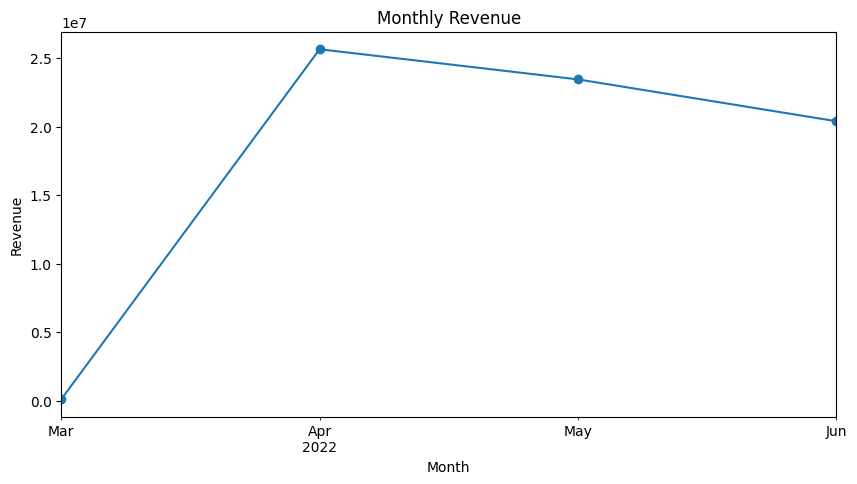

In [43]:
# Visualize the monthly revenue
monthly_revenue.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

## Revenue by category

In [44]:
category_revenue = (
    revenue_df.groupby('Category')['Amount']
    .sum()
    .sort_values(ascending=False)
)

category_revenue

,Amount
Category,
Set,34718582.0
kurta,18928035.0
Western Dress,9824156.0
Top,4793221.0
Ethnic Dress,715351.0
Blouse,409494.0
Bottom,132872.0
Saree,113696.0
Dupatta,915.0


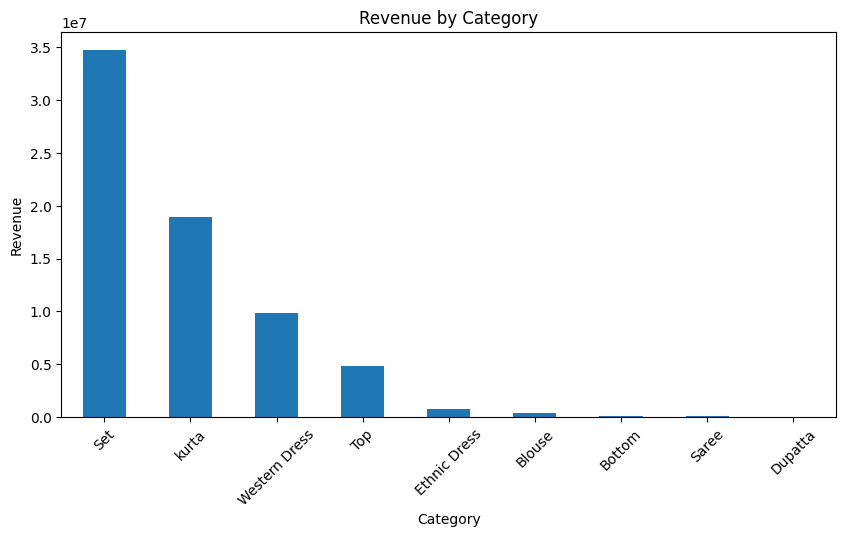

In [45]:
#visualization
category_revenue.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Revenue by Category')
plt.xlabel('Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

In [46]:
#Set and Kurta are the largest revenue-generating categories.

# Quantity vs Revenue

In [47]:
# find the amount, quantity, and number or orders against each category
category_performance = (
    revenue_df.groupby('Category')
    .agg(
        Revenue=('Amount', 'sum'),
        Quantity=('Qty', 'sum'),
        Orders=('Order ID', 'nunique')
    )
    .sort_values('Revenue', ascending=False)
)

category_performance

,Revenue,Quantity,Orders
Category,,,
Set,34718582.0,41798,39688
kurta,18928035.0,41697,38737
Western Dress,9824156.0,12895,12419
Top,4793221.0,9150,8721
Ethnic Dress,715351.0,993,981
Blouse,409494.0,815,768
Bottom,132872.0,375,347
Saree,113696.0,146,122
Dupatta,915.0,3,2


In [48]:
# Average order values
category_performance['AOV'] = (
    category_performance['Revenue'] /
    category_performance['Orders']
)

category_performance.sort_values('AOV', ascending=False)

,Revenue,Quantity,Orders,AOV
Category,,,,
Saree,113696.0,146,122,931.934426
Set,34718582.0,41798,39688,874.787896
Western Dress,9824156.0,12895,12419,791.058539
Ethnic Dress,715351.0,993,981,729.205912
Top,4793221.0,9150,8721,549.618278
Blouse,409494.0,815,768,533.195312
kurta,18928035.0,41697,38737,488.629347
Dupatta,915.0,3,2,457.500000
Bottom,132872.0,375,347,382.916427


In [49]:
# Saree generating the highest revenue per order

#Geographic analysis

In [50]:
df['ship-state'].unique()

array(['MAHARASHTRA', 'KARNATAKA', 'PUDUCHERRY', 'TAMIL NADU',
       'UTTAR PRADESH', 'CHANDIGARH', 'TELANGANA', 'ANDHRA PRADESH',
       'RAJASTHAN', 'DELHI', 'HARYANA', 'ASSAM', 'JHARKHAND',
       'CHHATTISGARH', 'ODISHA', 'KERALA', 'MADHYA PRADESH',
       'WEST BENGAL', 'NAGALAND', 'Gujarat', 'UTTARAKHAND', 'BIHAR',
       'JAMMU & KASHMIR', 'PUNJAB', 'HIMACHAL PRADESH',
       'ARUNACHAL PRADESH', 'MANIPUR', 'Goa', 'MEGHALAYA', 'GOA',
       'TRIPURA', 'LADAKH', 'DADRA AND NAGAR', 'SIKKIM', 'Delhi', nan,
       'ANDAMAN & NICOBAR ', 'Punjab', 'Rajshthan', 'Manipur',
       'rajasthan', 'Odisha', 'NL', 'Bihar', 'MIZORAM', 'punjab',
       'New Delhi', 'Rajasthan', 'Punjab/Mohali/Zirakpur', 'Puducherry',
       'delhi', 'RJ', 'Chandigarh', 'orissa', 'LAKSHADWEEP', 'goa', 'PB',
       'APO', 'Arunachal Pradesh', 'AR', 'Pondicherry', 'Sikkim',
       'Arunachal pradesh', 'Nagaland', 'bihar', 'Mizoram', 'rajsthan',
       'Orissa', 'Rajsthan', 'Meghalaya'], dtype=object)

In [51]:
# Let's find the total amount vs city
state_sales = (
    revenue_df.groupby('ship-state')['Amount']
    .sum()
    .sort_values(ascending=False)
)

state_sales.head(10)

,Amount
ship-state,
MAHARASHTRA,11952244.0
KARNATAKA,9433256.0
TELANGANA,6120438.0
UTTAR PRADESH,5964886.0
TAMIL NADU,5809927.0
DELHI,3806844.0
KERALA,3300356.0
WEST BENGAL,3095415.0
ANDHRA PRADESH,2794146.0


In [52]:
# Find the number of orders for each city
state_orders = (
    revenue_df.groupby('ship-state')['Order ID']
    .nunique()
    .sort_values(ascending=False)
)

state_orders.head(10)

,Order ID
ship-state,
MAHARASHTRA,17593
KARNATAKA,13769
TAMIL NADU,8850
TELANGANA,8675
UTTAR PRADESH,8230
DELHI,5389
KERALA,4897
WEST BENGAL,4651
ANDHRA PRADESH,4031


# Cancellation Investigation
`We've already found:`

`Overall cancellation rate = 14.21%`

`Merchant = 17.47%`

`Amazon = 12.79%`

`Now let's investigate why.`

In [53]:
cancel_analysis = (
    df.groupby(['Fulfilment', 'Category'])['Status']
    .apply(lambda x: (x == 'Cancelled').mean() * 100)
    .reset_index(name='Cancellation_Rate')
)

cancel_analysis.sort_values(
    'Cancellation_Rate',
    ascending=False
)

,Fulfilment,Category,Cancellation_Rate
12,Merchant,Saree,25.000000
9,Merchant,Blouse,21.367521
11,Merchant,Ethnic Dress,18.327974
10,Merchant,Bottom,18.229167
16,Merchant,kurta,18.164597
13,Merchant,Set,17.779587
15,Merchant,Western Dress,15.985077
14,Merchant,Top,15.215686
5,Amazon,Set,13.269382
8,Amazon,kurta,13.097912


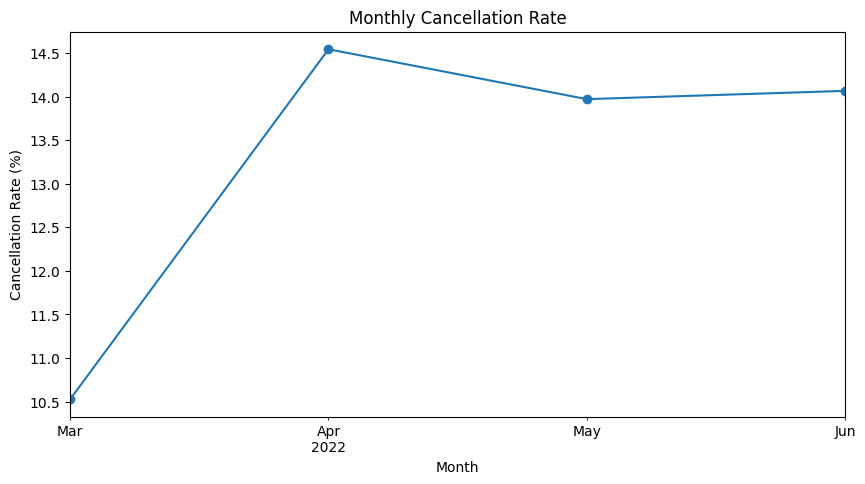

In [54]:
# Visualize and find the monthly cancelation trend
monthly_cancel = (
    df.groupby('Month')['Status']
    .apply(lambda x: (x == 'Cancelled').mean() * 100)
)

monthly_cancel.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title('Monthly Cancellation Rate')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [56]:
top_products = (
    revenue_df.groupby('SKU')
    .agg(
        Revenue=('Amount', 'sum'),
        Quantity=('Qty', 'sum'),
        Orders=('Order ID', 'nunique')
    )
    .sort_values('Revenue', ascending=False)
)

top_products.head(10)

,Revenue,Quantity,Orders
SKU,,,
J0230-SKD-M,480913.0,433,431
JNE3797-KR-L,439562.0,605,604
J0230-SKD-S,436032.0,390,389
JNE3797-KR-M,376370.0,515,510
JNE3797-KR-S,339192.0,461,460
JNE3797-KR-XL,277177.0,372,371
J0230-SKD-L,274189.0,250,249
SET268-KR-NP-XL,260156.0,344,343
JNE3797-KR-XS,257588.0,348,344


In [55]:
df['Size'].value_counts()

,count
Size,
M,22711
L,22132
XL,20876
XXL,18096
S,17090
3XL,14816
XS,11161
6XL,738
5XL,550


In [57]:
size_revenue = (
    revenue_df.groupby('Size')['Amount']
    .sum()
    .sort_values(ascending=False)
)

size_revenue

,Amount
Size,
M,12206398.0
L,11715110.0
XL,11049107.0
XXL,9507406.0
S,9360700.0
3XL,8230594.0
XS,6156409.0
6XL,533982.0
5XL,387126.0


In [58]:
size_quantity = (
    revenue_df.groupby('Size')['Qty']
    .sum()
    .sort_values(ascending=False)
)

size_quantity

,Qty
Size,
M,18789
L,18507
XL,17551
XXL,15322
S,14117
3XL,12654
XS,9076
6XL,655
5XL,480


In [59]:
b2b_analysis = (
    revenue_df.groupby('B2B')
    .agg(
        Revenue=('Amount', 'sum'),
        Orders=('Order ID', 'nunique'),
        Quantity=('Qty', 'sum')
    )
)

b2b_analysis

,Revenue,Orders,Quantity
B2B,,,
False,69086195.0,99592,107074
True,550127.0,718,798


In [60]:
b2b_analysis['AOV'] = (
    b2b_analysis['Revenue'] /
    b2b_analysis['Orders']
)

b2b_analysis

,Revenue,Orders,Quantity,AOV
B2B,,,,
False,69086195.0,99592,107074,693.692214
True,550127.0,718,798,766.193593
